In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
import warnings 
import sqlite3
from scipy.stats import ttest_ind
import scipy.stats as stats 
warnings.filterwarnings('ignore')

In [2]:
%pip install matplotlib seaborn scipy

Note: you may need to restart the kernel to use updated packages.


Loading the dataset

In [3]:
##creatng database connection
conn= sqlite3.connect('inventory.db')

##feth vendor summary data
df=pd.read_sql_query("select * from vendor_sales_summary",conn)
df.head()

,VendorNumber,VendorName,Brand,Description,PurchasePrice,ActualPrice,Volume,TotalPurchaseQuantity,TotalPurchaseDollars,TotalSalesQuantity,TotalSalesDollars,TotalSalesPrice,TotalExciseTax,FreightCost,GrossProfit,ProfitMargin,StockTurnover,SalesToPurchaseRatio
0,1128,BROWN-FORMAN CORP,1233,Jack Daniels No 7 Black,26.27,36.99,1750.0,145080,3811251.60,142049.0,5101919.51,672819.31,260999.20,68601.68,1290667.91,25.297693,97.910808,133.864673
1,4425,MARTIGNETTI COMPANIES,3405,Tito's Handmade Vodka,23.19,28.99,1750.0,164038,3804041.22,160247.0,4819073.49,561512.37,294438.66,144929.24,1015032.27,21.062810,97.688950,126.682999
2,17035,PERNOD RICARD USA,8068,Absolut 80 Proof,18.24,24.99,1750.0,187407,3418303.68,187140.0,4538120.60,461140.15,343854.07,123780.22,1119816.92,24.675786,99.857529,132.759433
3,3960,DIAGEO NORTH AMERICA INC,4261,Capt Morgan Spiced Rum,16.17,22.99,1750.0,201682,3261197.94,200412.0,4475972.88,420050.01,368242.80,257032.07,1214774.94,27.139908,99.370296,137.249347
4,3960,DIAGEO NORTH AMERICA INC,3545,Ketel One Vodka,21.89,29.99,1750.0,138109,3023206.01,135838.0,4223107.62,545778.28,249587.83,257032.07,1199901.61,28.412764,98.355647,139.689707


Exploratory Data Analysis 

Previously, we examined the variuos tables in database to identify key variables, understand their relationship, and determine which one should be included in the final analysis.

In this phase od EDA we will analyze the resultant table to gain insights into the distribution of each column. This will help us understand data patterns, identity anomalies. aand ensure data quality before proceeding with further analysis

In [4]:
## summary statistics 

df.describe().T

,count,mean,std,min,25%,50%,75%,max
VendorNumber,10692.0,10650.649458,18753.519148,2.000000,3951.000000,7153.000000,9552.000000,2.013590e+05
Brand,10692.0,18039.228769,12662.187074,58.000000,5793.500000,18761.500000,25514.250000,9.063100e+04
PurchasePrice,10692.0,24.385303,109.269375,0.360000,6.840000,10.455000,19.482500,5.681810e+03
ActualPrice,10692.0,35.643671,148.246016,0.490000,10.990000,15.990000,28.990000,7.499990e+03
Volume,10692.0,847.360550,664.309212,50.000000,750.000000,750.000000,750.000000,2.000000e+04
TotalPurchaseQuantity,10692.0,3140.886831,11095.086769,1.000000,36.000000,262.000000,1975.750000,3.376600e+05
TotalPurchaseDollars,10692.0,30106.693372,123067.799627,0.710000,453.457500,3655.465000,20738.245000,3.811252e+06
TotalSalesQuantity,10692.0,3077.482136,10952.851391,0.000000,33.000000,261.000000,1929.250000,3.349390e+05
TotalSalesDollars,10692.0,42239.074419,167655.265984,0.000000,729.220000,5298.045000,28396.915000,5.101920e+06
TotalSalesPrice,10692.0,18793.783627,44952.773386,0.000000,289.710000,2857.800000,16059.562500,6.728193e+05


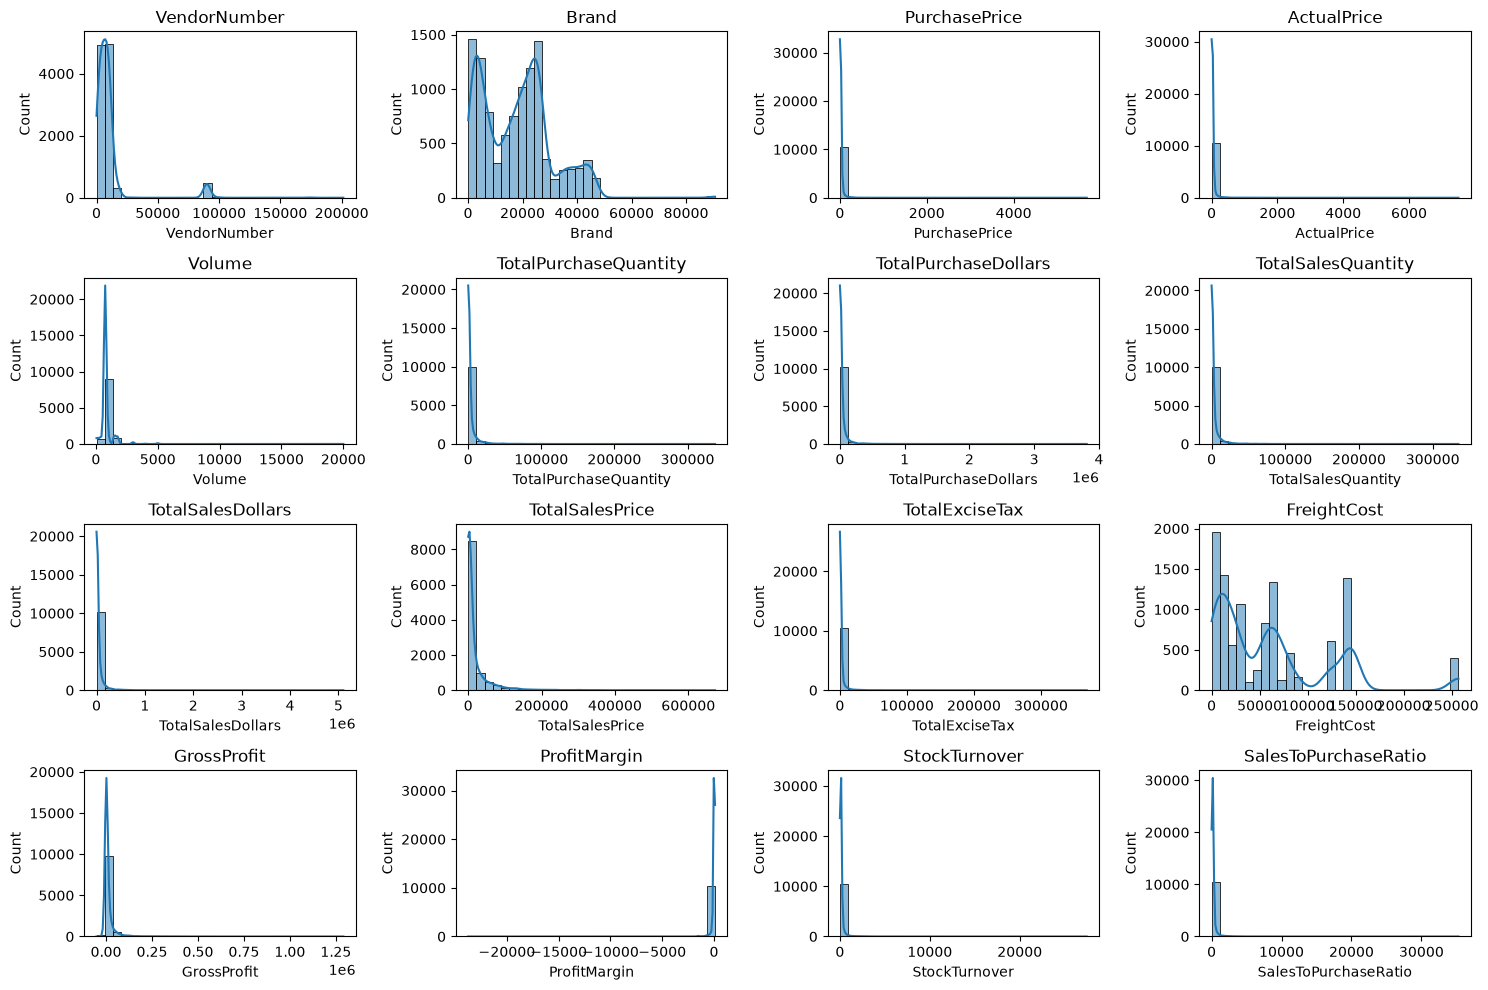

In [5]:
#distribution plots for numerical columns 
numerical_cols= df.select_dtypes(include=np.number).columns


plt.figure(figsize=(15,10))
for i, col in enumerate(numerical_cols):
    plt.subplot(4,4,i+1)  #adjust grid layout as needed 
    sns.histplot(df[col], kde=True,bins=30)
    plt.title(col)
    
plt.tight_layout()
plt.show()
    

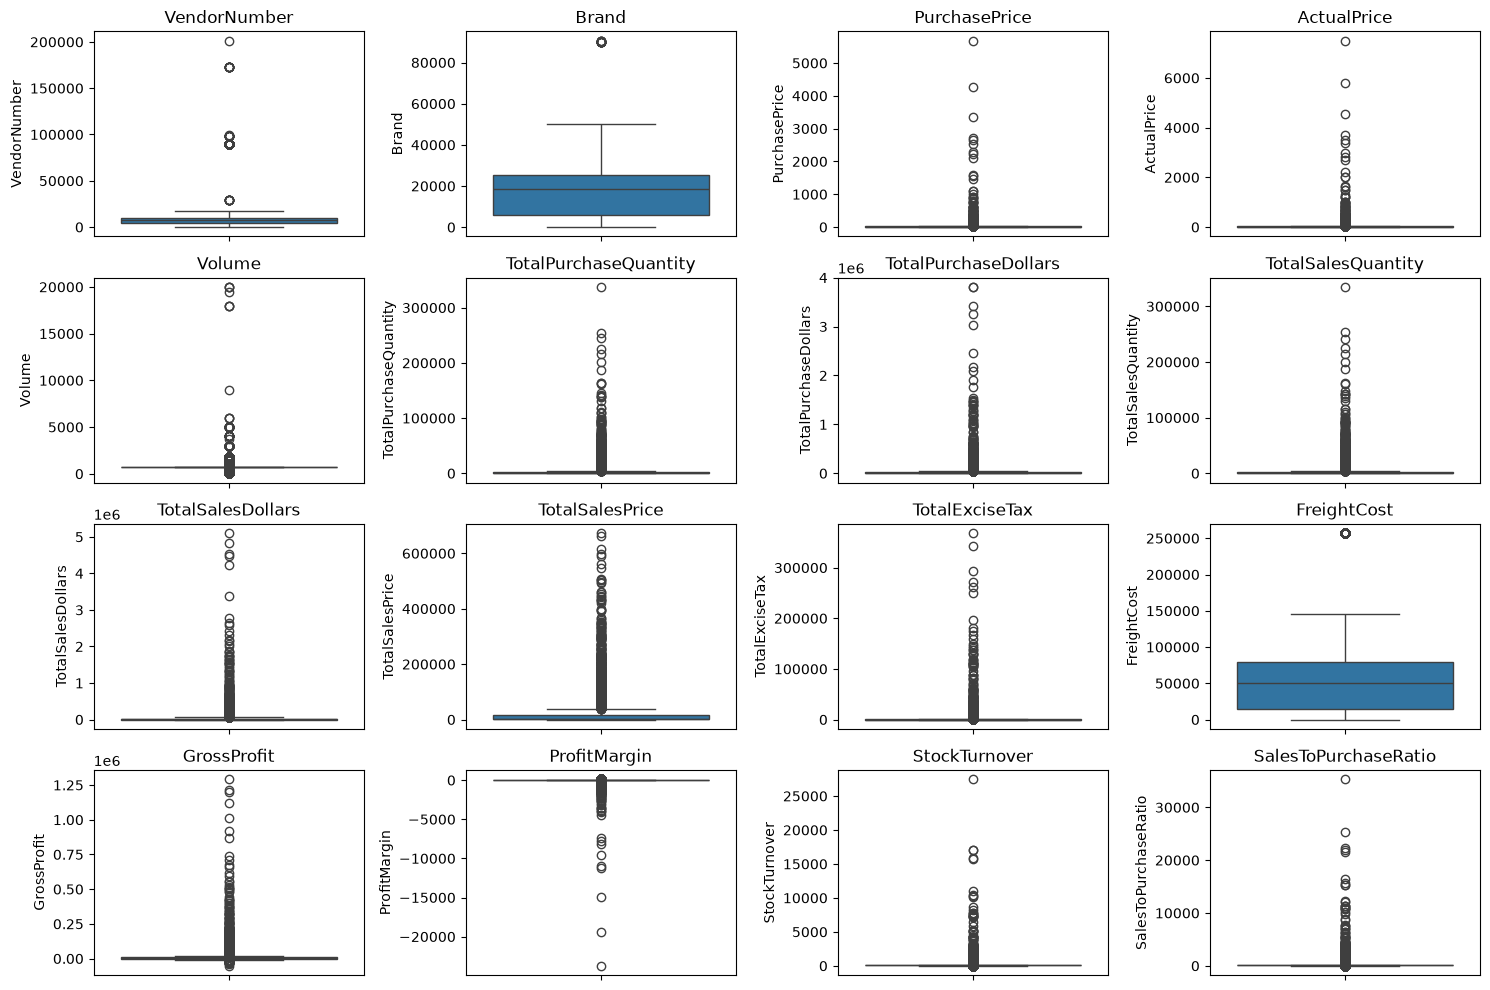

In [6]:
plt.figure(figsize=(15,10))
for i, col in enumerate(numerical_cols):
    plt.subplot(4,4,i+1)
    sns.boxplot(y=df[col])
    plt.title(col)
plt.tight_layout()
plt.show()
    

Summary statistics highlight 

negative and zero values:

Gross profit: minimum value is -52,002.78, indicating losses.Some products selling at discount lower than the purchase price.

Profit Margin: Has a min of - infinity which suggest cases where revenue is zero or even lower than cost 

Total Sales Quantity and Sales dollar: Minimum values are 0, meaning some products were purchased but never sold. These could be slow-moving or onsolete stock.

Outliers indicate by high standard deviations:

purchase and actual price: the max value (5,681.81 & 7,499.99) are significantly higher than the mean (24.39 & 35.64), indicating potential premium products.

Freight Cost: Huge variation, from (0.09 to 257,0332.07) suggest logistics inefficiencies or buk shipments 
Stock turnover: Range from 0 to 274.5, iplying some products sell extremly fast while other remain in stock indefinitely. Value more than 1 indicates that sold quantity for the product is higher that purchased quantity due to either sales are being fullfilled from older stock.

In [7]:
##lets filter the data by removing inconsistencies 

df= pd.read_sql_query(""" SELECT * FROM vendor_sales_summary
WHERE GrossProfit >0 
AND ProfitMargin >0 
AND TotalSalesQuantity >0""", conn)


In [8]:
df

,VendorNumber,VendorName,Brand,Description,PurchasePrice,ActualPrice,Volume,TotalPurchaseQuantity,TotalPurchaseDollars,TotalSalesQuantity,TotalSalesDollars,TotalSalesPrice,TotalExciseTax,FreightCost,GrossProfit,ProfitMargin,StockTurnover,SalesToPurchaseRatio
0,1128,BROWN-FORMAN CORP,1233,Jack Daniels No 7 Black,26.27,36.99,1750.0,145080,3811251.60,142049.0,5101919.51,672819.31,260999.20,68601.68,1290667.91,25.297693,97.910808,133.864673
1,4425,MARTIGNETTI COMPANIES,3405,Tito's Handmade Vodka,23.19,28.99,1750.0,164038,3804041.22,160247.0,4819073.49,561512.37,294438.66,144929.24,1015032.27,21.062810,97.688950,126.682999
2,17035,PERNOD RICARD USA,8068,Absolut 80 Proof,18.24,24.99,1750.0,187407,3418303.68,187140.0,4538120.60,461140.15,343854.07,123780.22,1119816.92,24.675786,99.857529,132.759433
3,3960,DIAGEO NORTH AMERICA INC,4261,Capt Morgan Spiced Rum,16.17,22.99,1750.0,201682,3261197.94,200412.0,4475972.88,420050.01,368242.80,257032.07,1214774.94,27.139908,99.370296,137.249347
4,3960,DIAGEO NORTH AMERICA INC,3545,Ketel One Vodka,21.89,29.99,1750.0,138109,3023206.01,135838.0,4223107.62,545778.28,249587.83,257032.07,1199901.61,28.412764,98.355647,139.689707
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8559,9815,WINE GROUP INC,8527,Concannon Glen Ellen Wh Zin,1.32,4.99,750.0,2,2.64,5.0,15.95,10.96,0.55,27100.41,13.31,83.448276,250.000000,604.166667
8560,8004,SAZERAC CO INC,5683,Dr McGillicuddy's Apple Pie,0.39,0.49,50.0,6,2.34,134.0,65.66,1.47,7.04,50293.62,63.32,96.436186,2233.333333,2805.982906
8561,3924,HEAVEN HILL DISTILLERIES,9123,Deep Eddy Vodka,0.74,0.99,50.0,2,1.48,2.0,1.98,0.99,0.10,14069.87,0.50,25.252525,100.000000,133.783784
8562,3960,DIAGEO NORTH AMERICA INC,6127,The Club Strawbry Margarita,1.47,1.99,200.0,1,1.47,72.0,143.28,77.61,15.12,257032.07,141.81,98.974037,7200.000000,9746.938776


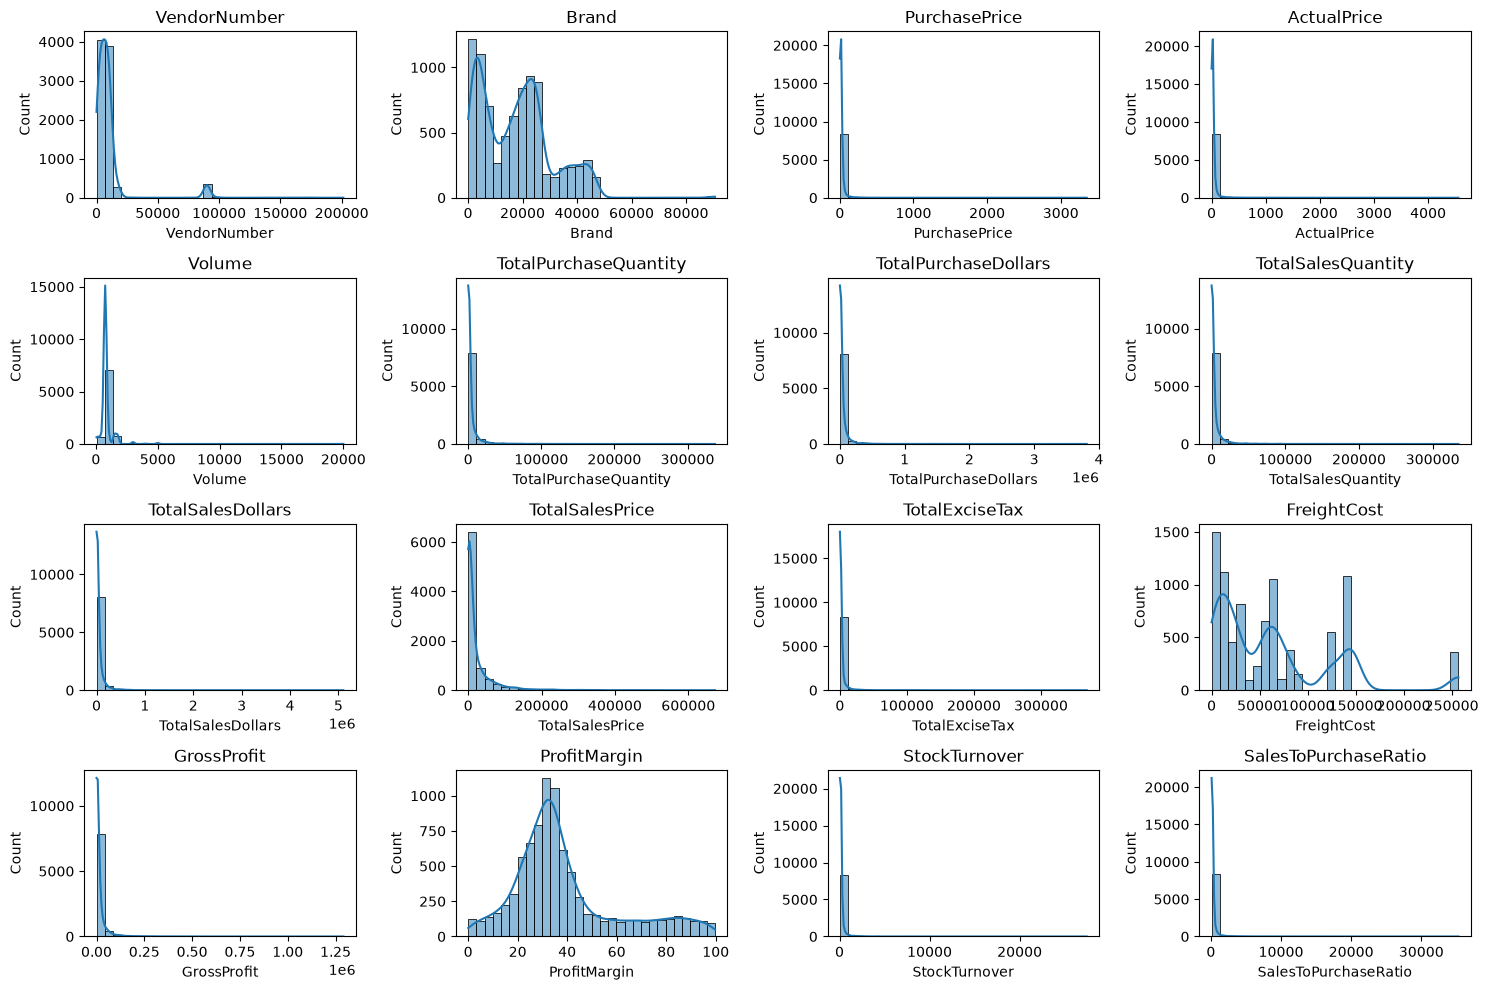

In [9]:
#distribution plots for numerical columns 
numerical_cols= df.select_dtypes(include=np.number).columns


plt.figure(figsize=(15,10))
for i, col in enumerate(numerical_cols):
    plt.subplot(4,4,i+1)  #adjust grid layout as needed 
    sns.histplot(df[col], kde=True,bins=30)
    plt.title(col)
    
plt.tight_layout()
plt.show()

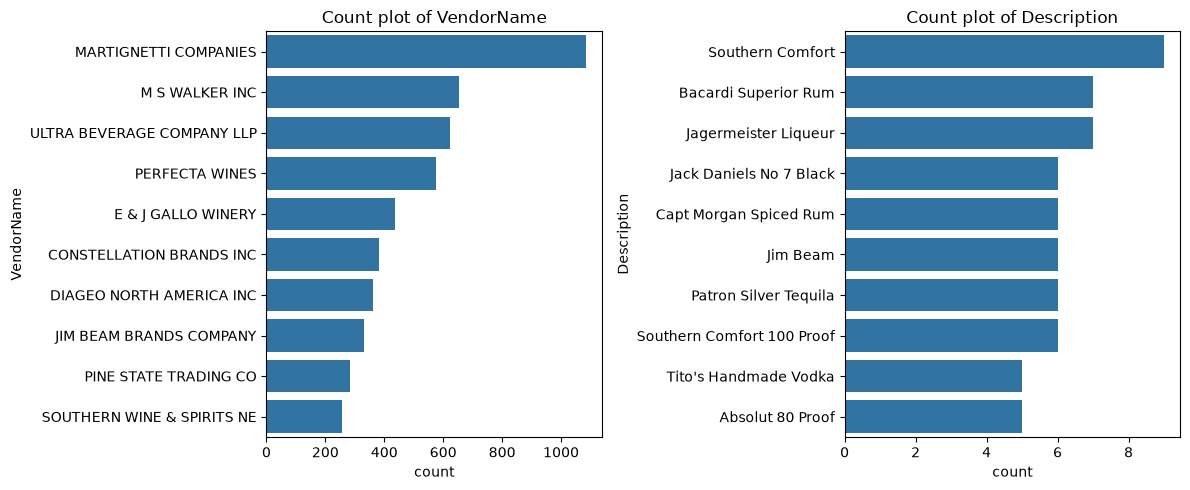

In [21]:
##count plot for ctegorical columns 
categorical_cols = ["VendorName","Description"]

plt.figure(figsize=(12,5))
for i, col in enumerate(categorical_cols):
    plt.subplot(1,2,i+1)
    sns.countplot(y=df[col], order=df[col].value_counts().index[:10]) ##Top 10 categories
    plt.title(f"Count plot of {col}")
plt.tight_layout()
plt.show()

My description plot is quite differnt from what i expected and from the results as well lets do it other time 


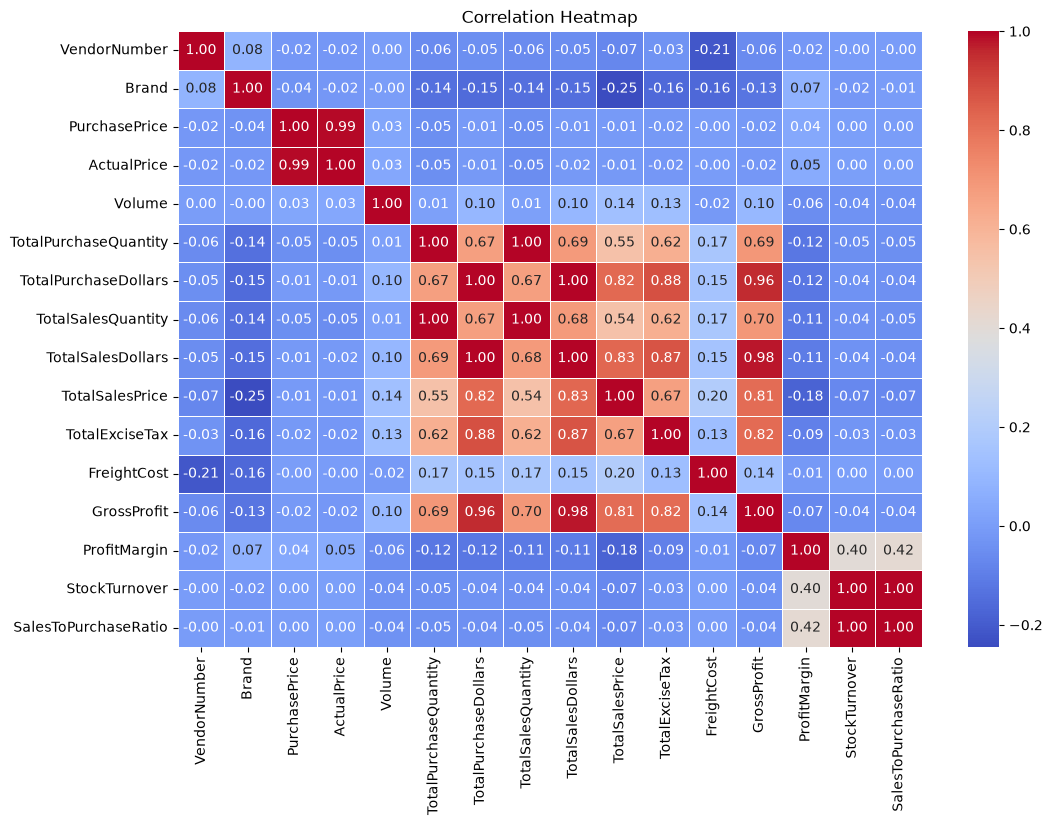

In [11]:
##corelation heatmap 
plt.figure(figsize=(12,8))
correlation_matrix = df[numerical_cols].corr()
sns.heatmap(correlation_matrix,annot=True, fmt=".2f", cmap="coolwarm",linewidths= 0.5)
plt.title("Correlation Heatmap")
plt.show()


### Correlation Insights

purchasePrice has weak correlations with TotalSalesDollar (-0.012) and grossProfit (-0.016), suggesting that price variation do not significantly impact sales revenue or profit.

strong correlation between total purchase quantity and total sales quantity(0.999), confirming efficient invemtory turnover.

Negative correlation between profit margin and total sales price (-0.179) suggest that as sales price increases, margin decrease,possibly due to competitive pricing pressures.

StockTurnover has weak negative correlations with both GrossProfit (-0.038) and profitMargin (-0.055), indicating that faster turnover doesnot necessarily results in higher profitability 

### Data Analysis 

identify brands that need promotional or pricing Adjustment which exhibit lower sales performance but higher profit margins

In [12]:
brand_performance=df.groupby('Description').agg({ 'TotalSalesDollars' :'sum', 'ProfitMargin': 'mean'}).reset_index()

In [13]:
low_sales_threshold =brand_performance ['TotalSalesDollars'].quantile(0.15)
high_margin_threshold =brand_performance ['ProfitMargin'].quantile(0.85)

In [14]:
low_sales_threshold

np.float64(560.299)

In [15]:
high_margin_threshold

np.float64(64.97017552750113)

In [16]:
#filter brands with low sales but high profit margins

target_brands = brand_performance[ (brand_performance['TotalSalesDollars'] <= low_sales_threshold)& (brand_performance['ProfitMargin']>= high_margin_threshold)]

print("Brand with Low Sales but High Profit Margin:")
display(target_brands.sort_values('TotalSalesDollars'))

Brand with Low Sales but High Profit Margin:


,Description,TotalSalesDollars,ProfitMargin
6199,Santa Rita Organic Svgn Bl,9.99,66.466466
2369,Debauchery Pnt Nr,11.58,65.975820
2070,Concannon Glen Ellen Wh Zin,15.95,83.448276
2188,Crown Royal Apple,27.86,89.806174
6237,Sauza Sprklg Wild Berry Marg,27.96,82.153076
...,...,...,...
5074,Nanbu Bijin Southern Beauty,535.68,76.747312
2271,Dad's Hat Rye Whiskey,538.89,81.851584
57,A Bichot Clos Marechaudes,539.94,67.740860
6245,Sbragia Home Ranch Merlot,549.75,66.444748


In [18]:
print("Brand performance:", brand_performance.shape)
print("Target brands:", target_brands.shape)

print(
    "Brand sales range:",
    brand_performance["TotalSalesDollars"].min(),
    "to",
    brand_performance["TotalSalesDollars"].max()
)

print(
    "Target sales range:",
    target_brands["TotalSalesDollars"].min(),
    "to",
    target_brands["TotalSalesDollars"].max()
)

Brand performance: (7707, 3)
Target brands: (198, 3)
Brand sales range: 4.99 to 7964746.76
Target sales range: 9.99 to 558.87


In [19]:
brand_performance = brand_performance[
    brand_performance["TotalSalesDollars"] < 10000
].copy()

print("Shape after filtering:", brand_performance.shape)
print("Maximum sales:", brand_performance["TotalSalesDollars"].max())

Shape after filtering: (4162, 3)
Maximum sales: 9999.47


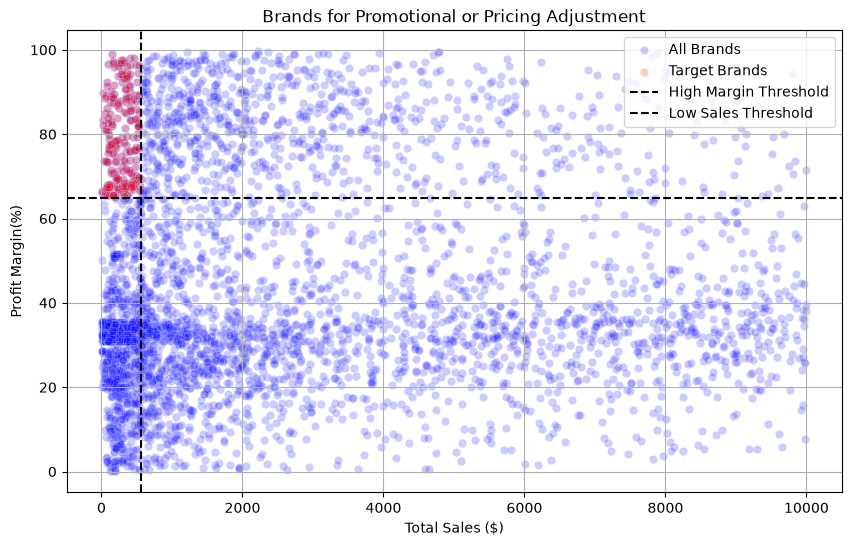

In [20]:
plt.figure(figsize=(10,6))
sns.scatterplot(data=brand_performance, x='TotalSalesDollars', y='ProfitMargin', color="blue", label= "All Brands", alpha=0.2)
sns.scatterplot(data=target_brands, x='TotalSalesDollars', y='ProfitMargin', color="red", label= "Target Brands", alpha=0.2)

plt.axhline(high_margin_threshold,linestyle='--', color= 'black', label="High Margin Threshold")
plt.axvline(low_sales_threshold,linestyle= '--', color= 'black', label= "Low Sales Threshold ")

plt.xlabel("Total Sales ($)")
plt.ylabel("Profit Margin(%)")
plt.title("Brands for Promotional or Pricing Adjustment")
plt.legend()
plt.grid(True)
plt.show()


Which vendor and brands demonstrate the highest sales performance 

In [23]:
#Top vendor and brands by sales performance 
top_vendors=  df.groupby("VendorName")["TotalSalesDollars"].sum().nlargest(10)
top_brands= df.groupby("Description")["TotalSalesDollars"].sum().nlargest(10)
top_vendors

VendorName
DIAGEO NORTH AMERICA INC      67990099.42
MARTIGNETTI COMPANIES         39330359.36
PERNOD RICARD USA             32063196.19
JIM BEAM BRANDS COMPANY       31423020.46
BACARDI USA INC               24854817.14
CONSTELLATION BRANDS INC      24218745.65
E & J GALLO WINERY            18399899.46
BROWN-FORMAN CORP             18247230.65
ULTRA BEVERAGE COMPANY LLP    16502544.31
M S WALKER INC                14706458.51
Name: TotalSalesDollars, dtype: float64

In [24]:
print("Checking top_brands...")

print("Variable exists:", "top_brands" in globals())

if "top_brands" in globals():
    print("Type:", type(top_brands))
    print("Shape:", top_brands.shape)
    display(top_brands.head(10))

Checking top_brands...
Variable exists: True
Type: <class 'pandas.Series'>
Shape: (10,)


Description
Jack Daniels No 7 Black    7964746.76
Tito's Handmade Vodka      7399657.58
Grey Goose Vodka           7209608.06
Capt Morgan Spiced Rum     6356320.62
Absolut 80 Proof           6244752.03
Jameson Irish Whiskey      5715759.69
Ketel One Vodka            5070083.56
Baileys Irish Cream        4150122.07
Kahlua                     3604858.66
Tanqueray                  3456697.90
Name: TotalSalesDollars, dtype: float64

In [37]:
display(top_brands)

Description
Jack Daniels No 7 Black    7964746.76
Tito's Handmade Vodka      7399657.58
Grey Goose Vodka           7209608.06
Capt Morgan Spiced Rum     6356320.62
Absolut 80 Proof           6244752.03
Jameson Irish Whiskey      5715759.69
Ketel One Vodka            5070083.56
Baileys Irish Cream        4150122.07
Kahlua                     3604858.66
Tanqueray                  3456697.90
Name: TotalSalesDollars, dtype: float64

In [74]:
def format_dollars(value):
    if value >= 100_000:
        return f" {value / 1_000_000:.2f}M"
    elif value >= 1_000:
        return f"{value / 1_000:.2f} K"
    else:
        return str(value)

In [40]:
top_brands.apply(lambda x: format_dollars(x) )

Description
Jack Daniels No 7 Black     7.964747M
Tito's Handmade Vodka       7.399658M
Grey Goose Vodka            7.209608M
Capt Morgan Spiced Rum      6.356321M
Absolut 80 Proof            6.244752M
Jameson Irish Whiskey       5.715760M
Ketel One Vodka             5.070084M
Baileys Irish Cream         4.150122M
Kahlua                      3.604859M
Tanqueray                   3.456698M
Name: TotalSalesDollars, dtype: str

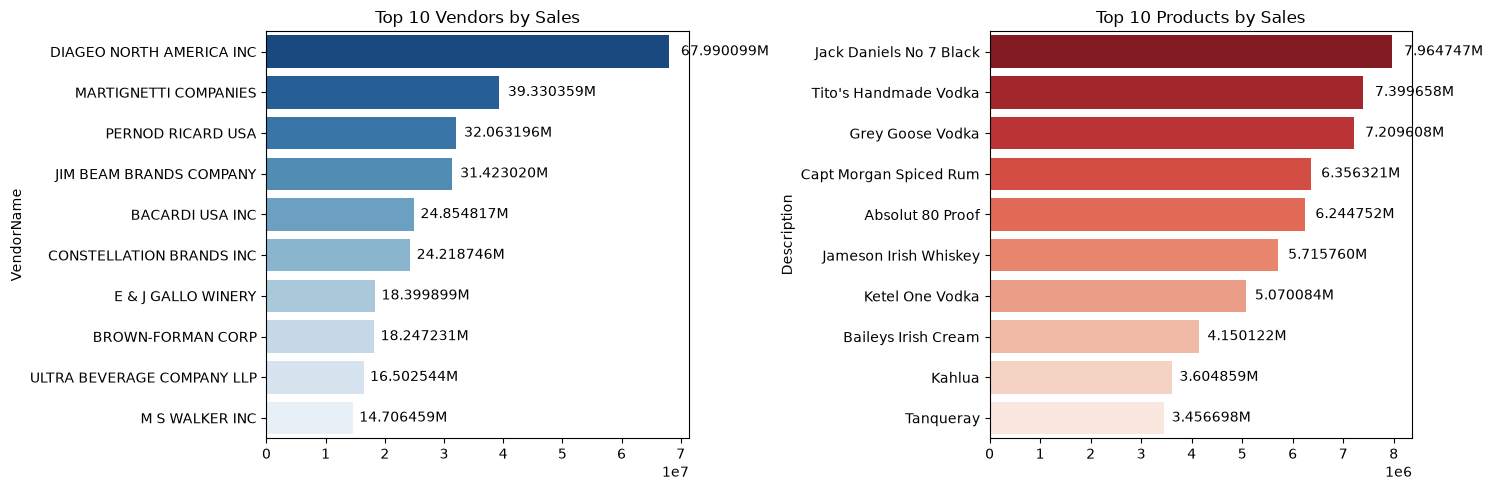

In [48]:
plt.figure(figsize=(15, 5))

# Plot for top vendors
plt.subplot(1, 2, 1)

ax1 = sns.barplot(
    y=top_vendors.index,
    x=top_vendors.values,
    palette="Blues_r"
)
plt.title("Top 10 Vendors by Sales")

for bar in ax1.patches:
    ax1.text(
        bar.get_width() + bar.get_width() * 0.02,
        bar.get_y() + bar.get_height() / 2,
        format_dollars(bar.get_width()),
        ha="left", va="center", fontsize=10, color="black"
    )

# Plot for top brands
plt.subplot(1, 2, 2)

ax2 = sns.barplot(
    y=top_brands.index,
    x=top_brands.values,
    palette="Reds_r"
)
plt.title("Top 10 Products by Sales")

for bar in ax2.patches:
    ax2.text(
        bar.get_width() + bar.get_width() * 0.02,
        bar.get_y() + bar.get_height() / 2,
        format_dollars(bar.get_width()),
        ha="left", va="center", fontsize=10, color="black"
    )

plt.tight_layout()
plt.show()

Which vendors contribute the most to total purhase dollars?

In [57]:
df.groupby('VendorName').agg({'TotalPurchaseDollars': 'sum', 'GrossProfit': 'sum', 'TotalSalesDollars' :'sum'}).reset_index()

,VendorName,TotalPurchaseDollars,GrossProfit,TotalSalesDollars
0,ADAMBA IMPORTS INTL INC,446.16,258.37,704.53
1,ALISA CARR BEVERAGES,25698.12,78772.82,104470.94
2,ALTAMAR BRANDS LLC,11706.20,4000.61,15706.81
3,AMERICAN SPIRITS EXCHANGE,934.08,577.08,1511.16
4,AMERICAN VINTAGE BEVERAGE,104435.68,35167.85,139603.53
...,...,...,...,...
114,WEIN BAUER INC,42694.64,13522.49,56217.13
115,WESTERN SPIRITS BEVERAGE CO,298416.86,106837.97,405254.83
116,WILLIAM GRANT & SONS INC,5876538.26,1693337.94,7569876.20
117,WINE GROUP INC,5203801.17,3100242.11,8304043.28


In [59]:
vendor_performance = (
    df.groupby("VendorName", as_index=False)["TotalPurchaseDollars"]
    .sum()
)

In [65]:
vendor_performance = df.groupby("VendorName", as_index=False).agg({
    "TotalPurchaseDollars": "sum",
    "TotalSalesDollars": "sum",
    "GrossProfit": "sum",
    "ProfitMargin": "mean"
})

vendor_performance["PurchaseContribution%"] = (
    vendor_performance["TotalPurchaseDollars"]
    / vendor_performance["TotalPurchaseDollars"].sum()
) * 100

print(vendor_performance.columns.tolist())

['VendorName', 'TotalPurchaseDollars', 'TotalSalesDollars', 'GrossProfit', 'ProfitMargin', 'PurchaseContribution%']


In [76]:
vendor_performance=round(vendor_performance.sort_values('PurchaseContribution%', ascending= False),2)

In [77]:
#display Top 10 Vendors 

top_vendors= vendor_performance.head(10)
top_vendors['TotalSalesDollars']= top_vendors['TotalSalesDollars'].apply(format_dollars)
top_vendors['TotalPurchaseDollars']= top_vendors['TotalPurchaseDollars'].apply(format_dollars)
top_vendors['GrossProfit']= top_vendors['GrossProfit'].apply(format_dollars)
top_vendors


,VendorName,TotalPurchaseDollars,TotalSalesDollars,GrossProfit,ProfitMargin,PurchaseContribution%
25,DIAGEO NORTH AMERICA INC,50.10M,67.99M,17.89M,33.01,16.30
57,MARTIGNETTI COMPANIES,25.50M,39.33M,13.83M,43.60,8.30
68,PERNOD RICARD USA,23.85M,32.06M,8.21M,33.84,7.76
46,JIM BEAM BRANDS COMPANY,23.49M,31.42M,7.93M,33.93,7.64
6,BACARDI USA INC,17.43M,24.85M,7.42M,39.44,5.67
20,CONSTELLATION BRANDS INC,15.27M,24.22M,8.95M,37.57,4.97
11,BROWN-FORMAN CORP,13.24M,18.25M,5.01M,34.24,4.31
30,E & J GALLO WINERY,12.07M,18.40M,6.33M,32.77,3.93
106,ULTRA BEVERAGE COMPANY LLP,11.17M,16.50M,5.34M,41.10,3.63
53,M S WALKER INC,9.76M,14.71M,4.94M,40.55,3.18


In [92]:
top_vendors['PurchaseContribution%'].sum()

np.float64(65.69000000000001)

In [93]:
top_vendors['Cumulative_Contribution%']= top_vendors['PurchaseContribution%'].cumsum()
top_vendors

,VendorName,TotalPurchaseDollars,TotalSalesDollars,GrossProfit,ProfitMargin,PurchaseContribution%,Cumulative_Contribution%
25,DIAGEO NORTH AMERICA INC,50.10M,67.99M,17.89M,33.01,16.30,16.30
57,MARTIGNETTI COMPANIES,25.50M,39.33M,13.83M,43.60,8.30,24.60
68,PERNOD RICARD USA,23.85M,32.06M,8.21M,33.84,7.76,32.36
46,JIM BEAM BRANDS COMPANY,23.49M,31.42M,7.93M,33.93,7.64,40.00
6,BACARDI USA INC,17.43M,24.85M,7.42M,39.44,5.67,45.67
20,CONSTELLATION BRANDS INC,15.27M,24.22M,8.95M,37.57,4.97,50.64
11,BROWN-FORMAN CORP,13.24M,18.25M,5.01M,34.24,4.31,54.95
30,E & J GALLO WINERY,12.07M,18.40M,6.33M,32.77,3.93,58.88
106,ULTRA BEVERAGE COMPANY LLP,11.17M,16.50M,5.34M,41.10,3.63,62.51
53,M S WALKER INC,9.76M,14.71M,4.94M,40.55,3.18,65.69


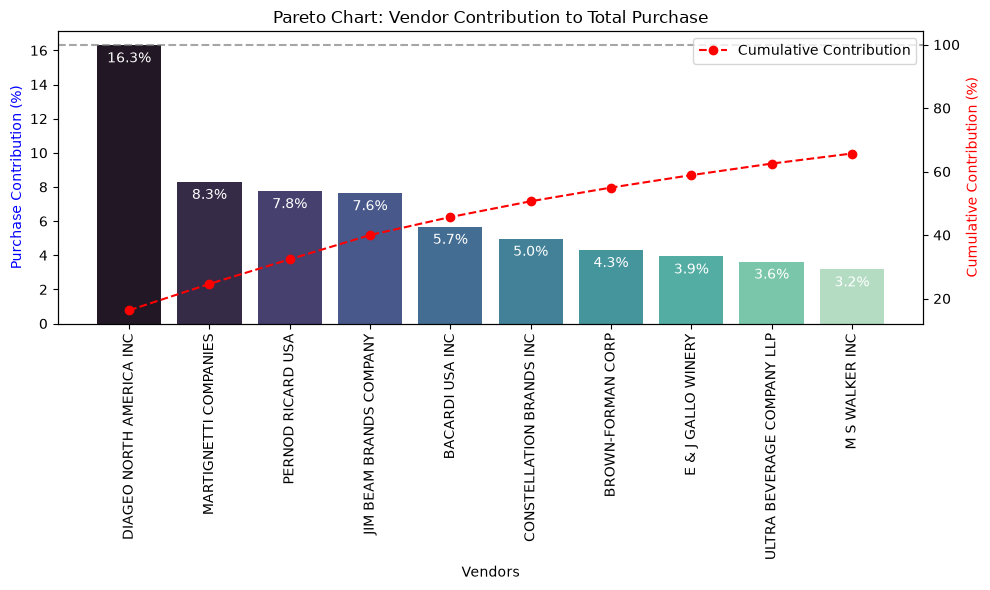

In [96]:

fig, ax1 = plt.subplots(figsize=(10, 6))

# Bar plot: purchase contribution
sns.barplot(
    x=top_vendors["VendorName"],
    y=top_vendors["PurchaseContribution%"],
    palette="mako",
    ax=ax1
)

for i, value in enumerate(top_vendors["PurchaseContribution%"]):
    ax1.text(
        i, value - 1, f"{value:.1f}%",
        ha="center", fontsize=10, color="white"
    )

# Line plot: cumulative contribution
ax2 = ax1.twinx()
ax2.plot(
    top_vendors["VendorName"],
    top_vendors["Cumulative_Contribution%"],
    color="red",
    marker="o",
    linestyle="dashed",
    label="Cumulative Contribution"
)

ax1.set_xticks(range(len(top_vendors)))
ax1.set_xticklabels(top_vendors["VendorName"], rotation=90)

ax1.set_ylabel("Purchase Contribution (%)", color="blue")
ax2.set_ylabel("Cumulative Contribution (%)", color="red")
ax1.set_xlabel("Vendors")
ax1.set_title("Pareto Chart: Vendor Contribution to Total Purchase")

ax2.axhline(y=100, color="gray", linestyle="dashed", alpha=0.7)
ax2.legend(loc="upper right")

plt.tight_layout()
plt.show()


In [95]:
print(top_vendors.columns.tolist())

['VendorName', 'TotalPurchaseDollars', 'TotalSalesDollars', 'GrossProfit', 'ProfitMargin', 'PurchaseContribution%', 'Cumulative_Contribution%']


how much of total procurement is dependent on the top vendors?

In [97]:
print(f" Total purcase contribution of top 10 vendor is {round(top_vendors['PurchaseContribution%'].sum(),2)} %")

 Total purcase contribution of top 10 vendor is 65.69 %


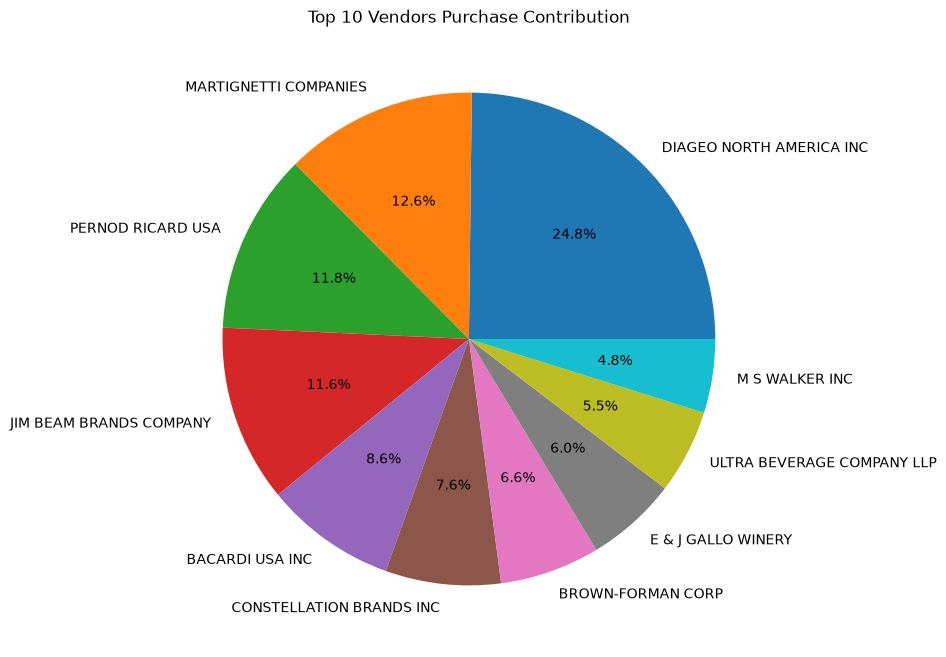

In [98]:
plt.figure(figsize=(8, 8))

plt.pie(
    top_vendors["PurchaseContribution%"],
    labels=top_vendors["VendorName"],
    autopct="%1.1f%%"
)

plt.title("Top 10 Vendors Purchase Contribution")
plt.show()

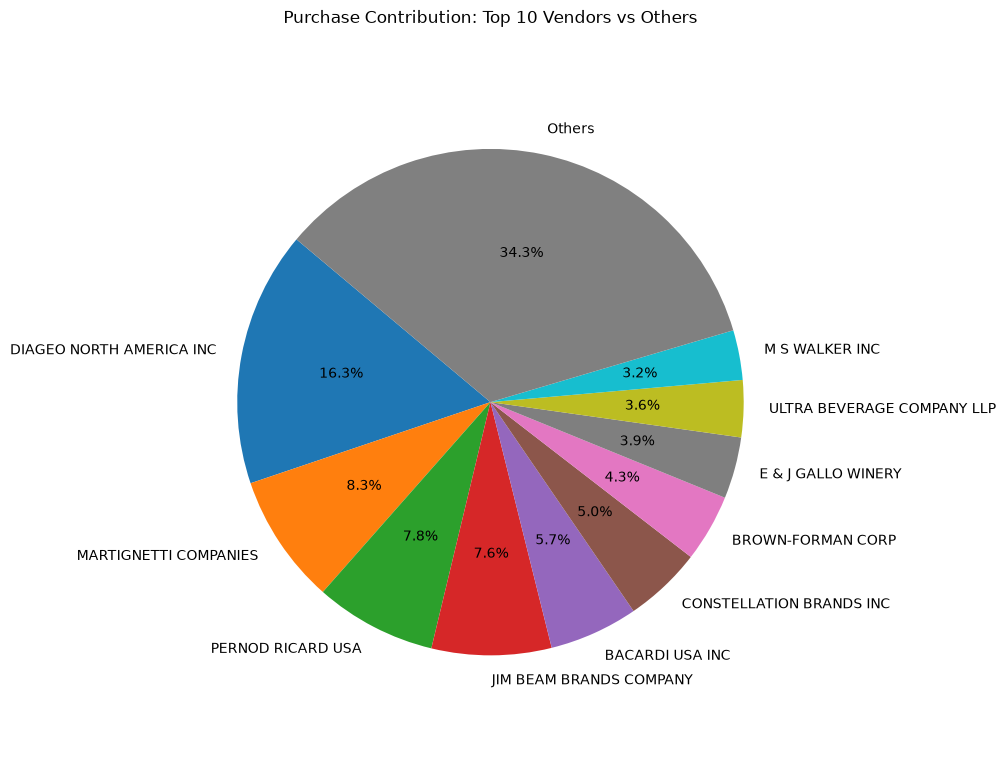

In [100]:

top10_total = top_vendors["PurchaseContribution%"].sum()
others = 100 - top10_total

labels = list(top_vendors["VendorName"]) + ["Others"]
values = list(top_vendors["PurchaseContribution%"]) + [others]

colors = plt.cm.tab10.colors[:10] + ("gray",)

plt.figure(figsize=(10, 8))

plt.pie(
    values,
    labels=labels,
    colors=colors,
    autopct="%1.1f%%",
    startangle=140
)

plt.title("Purchase Contribution: Top 10 Vendors vs Others")
plt.axis("equal")
plt.tight_layout()
plt.show()


Does purchasing in bulk reduce the unit price, and what is optimal purchase volume for cost savings?

In [108]:
df["UnitPurchasePrice"] = (
    df["TotalPurchaseDollars"] / df["TotalPurchaseQuantity"]
)

In [112]:

df["OrderSize"] = pd.qcut(
    df["TotalPurchaseQuantity"],
    q=3,
    labels=["Small", "Medium", "Large"]
)


In [114]:
df[['OrderSize','TotalPurchaseQuantity']]

,OrderSize,TotalPurchaseQuantity
0,Large,145080
1,Large,164038
2,Large,187407
3,Large,201682
4,Large,138109
...,...,...
8559,Small,2
8560,Small,6
8561,Small,2
8562,Small,1


In [115]:
df.groupby('OrderSize')[['UnitPurchasePrice']].mean()

,UnitPurchasePrice
OrderSize,
Small,39.068186
Medium,15.486414
Large,10.777625


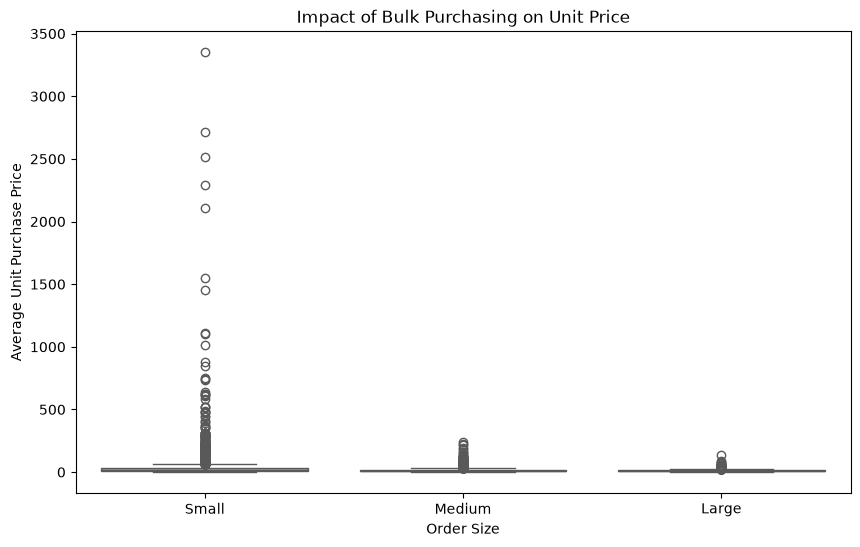

In [116]:
plt.figure(figsize=(10,6))
sns.boxplot(data=df, x="OrderSize", y="UnitPurchasePrice", palette="Set2")
plt.title("Impact of Bulk Purchasing on Unit Price")
plt.xlabel("Order Size")
plt.ylabel("Average Unit Purchase Price")
plt.show()

In [102]:

df["QuantityRange"] = pd.cut(
    df["TotalPurchaseQuantity"],
    bins=[0, 10, 50, 100, 500, float("inf")],
    labels=["1-10", "11-50", "51-100", "101-500", "500+"]
)

bulk_analysis = df.groupby(
    "QuantityRange", observed=False
).agg(
    AverageUnitPrice=("PurchasePrice", "mean"),
    AverageQuantity=("TotalPurchaseQuantity", "mean"),
    NumberOfRecords=("TotalPurchaseQuantity", "count")
).reset_index()

print(bulk_analysis)


  QuantityRange  AverageUnitPrice  AverageQuantity  NumberOfRecords
0          1-10         76.953937         4.499348              767
1         11-50         28.410166        24.770607             1565
2        51-100         15.540122        73.233232              656
3       101-500         16.145325       256.025623             1444
4          500+         11.988831      7706.564860             4132


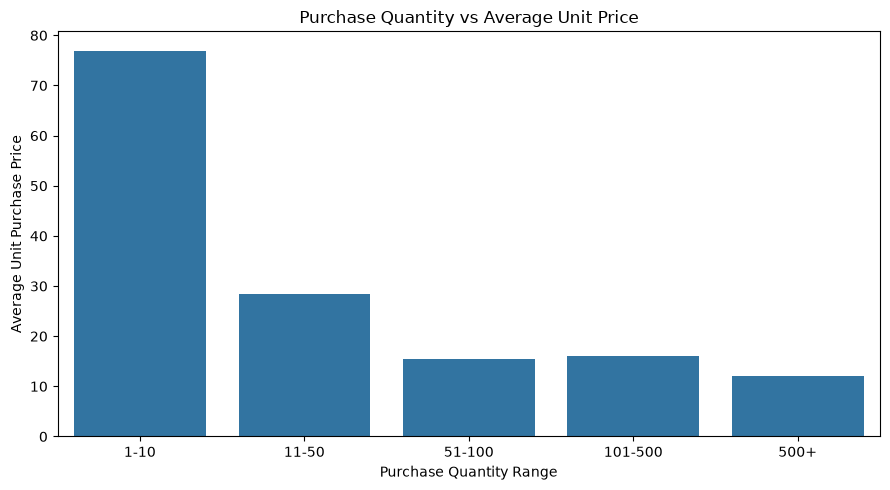

In [103]:

plt.figure(figsize=(9, 5))

sns.barplot(
    data=bulk_analysis,
    x="QuantityRange",
    y="AverageUnitPrice"
)

plt.xlabel("Purchase Quantity Range")
plt.ylabel("Average Unit Purchase Price")
plt.title("Purchase Quantity vs Average Unit Price")
plt.tight_layout()
plt.show()


Vendors buying in bulk (Larger Order Size) get the lowest unit price ($10.78 per unit), meaning higher margin if they can manage inventory efficiency
the price difference small and larger order in substntial(72% reduction in unit cost)
this suggest that bulk pricing startegies successfully enourage vendons to purchase in larger Volumne, leading to higher overall sales despite lower per unit revenue

Which vendors has low inventory turnover 

In [131]:
df['StockTurnover'] = (
    df['TotalSalesQuantity'] / df['TotalPurchaseQuantity']
) * 100

In [132]:
df[df['StockTurnover'] < 1]

,VendorNumber,VendorName,Brand,Description,PurchasePrice,ActualPrice,Volume,TotalPurchaseQuantity,TotalPurchaseDollars,TotalSalesQuantity,...,TotalSalesPrice,TotalExciseTax,FreightCost,GrossProfit,ProfitMargin,StockTurnover,SalesToPurchaseRatio,QuantityRange,UnitPurchasePrice,OrderSize


In [123]:
df['StockTurnover'].describe()

count     8564.000000
mean       203.205374
std        668.624769
min         42.857143
25%         94.526492
50%        100.000000
75%        112.068272
max      27450.000000
Name: StockTurnover, dtype: float64

In [133]:
print(df['StockTurnover'].dtype)
print(df['StockTurnover'].isna().sum())
print(df['StockTurnover'].head(10))

float64
0
0     97.910808
1     97.688950
2     99.857529
3     99.370296
4     98.355647
5    102.197984
6     98.366839
7     91.869803
8     98.525617
9     98.341998
Name: StockTurnover, dtype: float64


In [125]:
df[['TotalSalesDollars', 'TotalPurchaseDollars', 'StockTurnover']].head(10)

,TotalSalesDollars,TotalPurchaseDollars,StockTurnover
0,5101919.51,3811251.60,97.910808
1,4819073.49,3804041.22,97.688950
2,4538120.60,3418303.68,99.857529
3,4475972.88,3261197.94,99.370296
4,4223107.62,3023206.01,98.355647
5,3383912.40,2466635.93,102.197984
6,2773367.73,2177285.08,98.366839
7,2592041.35,2088334.84,91.869803
8,2640491.19,1903739.55,98.525617
9,2435393.39,1773427.14,98.341998


In [126]:
print(df.columns.tolist())

print(df[
    ['TotalSalesDollars', 'TotalPurchaseDollars', 'StockTurnover']
].head(10).to_string(index=False))

['VendorNumber', 'VendorName', 'Brand', 'Description', 'PurchasePrice', 'ActualPrice', 'Volume', 'TotalPurchaseQuantity', 'TotalPurchaseDollars', 'TotalSalesQuantity', 'TotalSalesDollars', 'TotalSalesPrice', 'TotalExciseTax', 'FreightCost', 'GrossProfit', 'ProfitMargin', 'StockTurnover', 'SalesToPurchaseRatio', 'QuantityRange', 'UnitPurchasePrice', 'OrderSize']
 TotalSalesDollars  TotalPurchaseDollars  StockTurnover
        5101919.51            3811251.60      97.910808
        4819073.49            3804041.22      97.688950
        4538120.60            3418303.68      99.857529
        4475972.88            3261197.94      99.370296
        4223107.62            3023206.01      98.355647
        3383912.40            2466635.93     102.197984
        2773367.73            2177285.08      98.366839
        2592041.35            2088334.84      91.869803
        2640491.19            1903739.55      98.525617
        2435393.39            1773427.14      98.341998


In [127]:
df[['StockTurnover']].describe()

,StockTurnover
count,8564.000000
mean,203.205374
std,668.624769
min,42.857143
25%,94.526492
50%,100.000000
75%,112.068272
max,27450.000000


In [134]:
df[['TotalSalesQuantity',
    'TotalPurchaseQuantity',
    'TotalSalesDollars',
    'TotalPurchaseDollars',
    'StockTurnover',
    'SalesToPurchaseRatio']].head(10)

,TotalSalesQuantity,TotalPurchaseQuantity,TotalSalesDollars,TotalPurchaseDollars,StockTurnover,SalesToPurchaseRatio
0,142049.0,145080,5101919.51,3811251.60,97.910808,133.864673
1,160247.0,164038,4819073.49,3804041.22,97.688950,126.682999
2,187140.0,187407,4538120.60,3418303.68,99.857529,132.759433
3,200412.0,201682,4475972.88,3261197.94,99.370296,137.249347
4,135838.0,138109,4223107.62,3023206.01,98.355647,139.689707
5,141860.0,138809,3383912.40,2466635.93,102.197984,137.187347
6,69627.0,70783,2773367.73,2177285.08,98.366839,127.377336
7,148265.0,161386,2592041.35,2088334.84,91.869803,124.120007
8,90481.0,91835,2640491.19,1903739.55,98.525617,138.700233
9,107061.0,108866,2435393.39,1773427.14,98.341998,137.326949


how much capital is locked in unsold inventory per vendor, and which vendors contribute the most to it 

In [137]:
df["UnsoldInventoryValue"] = (df["TotalPurchaseQuantity"] - df["TotalSalesQuantity"]) * df["PurchasePrice"]
print('Total Unsold Capital:', format_dollars(df["UnsoldInventoryValue"].sum()))

Total Unsold Capital:  2.71M


In [142]:
#Aggregate Capital Loked per Vendor

inventory_value_per_vendor = df.groupby ("VendorName") ["UnsoldInventoryValue"].sum().reset_index()

# Sort Vendor with the Highest Locked Capital

inventory_value_per_vendor = inventory_value_per_vendor.sort_values(by="UnsoldInventoryValue", ascending = False)
inventory_value_per_vendor['UnsoldInventoryValue']= inventory_value_per_vendor['UnsoldInventoryValue'].apply(format_dollars)
inventory_value_per_vendor.head(10)

,VendorName,UnsoldInventoryValue
25,DIAGEO NORTH AMERICA INC,0.72M
46,JIM BEAM BRANDS COMPANY,0.55M
68,PERNOD RICARD USA,0.47M
116,WILLIAM GRANT & SONS INC,0.40M
30,E & J GALLO WINERY,0.23M
79,SAZERAC CO INC,0.20M
11,BROWN-FORMAN CORP,0.18M
20,CONSTELLATION BRANDS INC,0.13M
61,MOET HENNESSY USA INC,0.13M
77,REMY COINTREAU USA INC,0.12M


what is the 95% cofidence interval for profit margin of top- performing and low- performing vendor 

In [144]:
top_threshold = df["TotalSalesDollars"].quantile(0.75)
low_threshold = df["TotalSalesDollars"].quantile(0.25)

In [148]:
top_vendors= df[df["TotalSalesDollars"] >= top_threshold] ["ProfitMargin"].dropna()
low_vendors = df[df["TotalSalesDollars"] <= low_threshold]["ProfitMargin"].dropna()

In [149]:
top_vendors

0       25.297693
1       21.062810
2       24.675786
3       27.139908
4       28.412764
          ...    
3523    79.684817
3681    85.782102
4751    93.085860
4920    95.012530
5050    94.271857
Name: ProfitMargin, Length: 2141, dtype: float64

In [150]:
def confidence_interval(data, confidence = 0.95):
    mean_val = np.mean(data)
    std_err = np.std(data, ddof=1)/ np.sqrt(len(data)) #standard error
    t_critical = stats.t.ppf((1+ confidence) / 2, df=len(data) -1)
    margin_of_error = t_critical * std_err
    return mean_val,mean_val - margin_of_error,mean_val+ margin_of_error

Top vendors 95% CI: (30.74, 31.61), Mean: 31.18
Low vendors 95% CI: (40.50, 42.64), Mean: 41.57


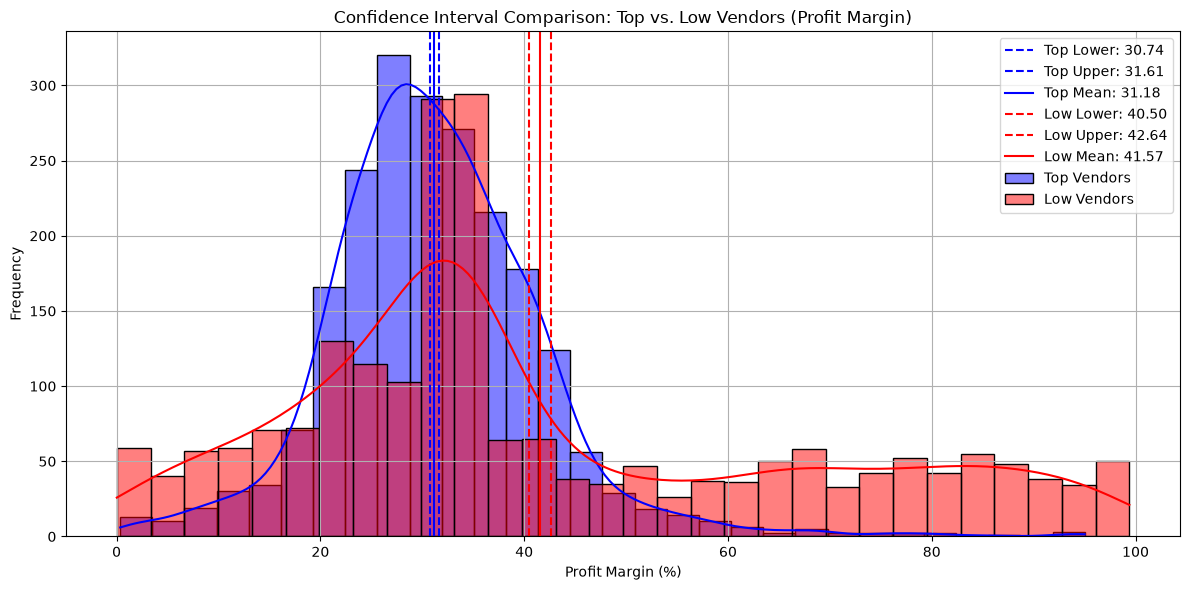

In [155]:

top_mean, top_lower, top_upper = confidence_interval(top_vendors)
low_mean, low_lower, low_upper = confidence_interval(low_vendors)

print(f"Top vendors 95% CI: ({top_lower:.2f}, {top_upper:.2f}), Mean: {top_mean:.2f}")
print(f"Low vendors 95% CI: ({low_lower:.2f}, {low_upper:.2f}), Mean: {low_mean:.2f}")

plt.figure(figsize=(12, 6))

# Top vendors
sns.histplot(top_vendors, kde=True, color="blue", bins=30, alpha=0.5, label="Top Vendors")
plt.axvline(top_lower, color="blue", linestyle="--", label=f"Top Lower: {top_lower:.2f}")
plt.axvline(top_upper, color="blue", linestyle="--", label=f"Top Upper: {top_upper:.2f}")
plt.axvline(top_mean, color="blue", linestyle="-", label=f"Top Mean: {top_mean:.2f}")

# Low vendors
sns.histplot(low_vendors, kde=True, color="red", bins=30, alpha=0.5, label="Low Vendors")
plt.axvline(low_lower, color="red", linestyle="--", label=f"Low Lower: {low_lower:.2f}")
plt.axvline(low_upper, color="red", linestyle="--", label=f"Low Upper: {low_upper:.2f}")
plt.axvline(low_mean, color="red", linestyle="-", label=f"Low Mean: {low_mean:.2f}")

# Finalize plot
plt.title("Confidence Interval Comparison: Top vs. Low Vendors (Profit Margin)")
plt.xlabel("Profit Margin (%)")
plt.ylabel("Frequency")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


The confidene interval for low performing vendors (40.48% to 42.62%) is signifcantly higher thaan of top performing vendors (30.74%  to 31.61%)
this suggest that vendor with lower sales trend to maintain higher profit margins, potentially due to premium pricing or lower operational costs.
For high-pperforming vendor: if they aim to improve profibility,they could exloore selective price adjustments, cost optimisation or bundling strategies.
For low-performing Vendor: Despite higher margns, their low sales volume might indicate a need for better marketing, competitive pricing, or improved distribution startegies 
    